<a href="https://colab.research.google.com/github/fawaztanigbola/Nigeria-ForeCasting-Model/blob/main/ERA5_And_DEM_Dataset_Download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing required libraries and tools.

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

# Main project folder
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project"
)

# ERA5 folders
ERA5_DIR = PROJECT_DIR / "ERA5"
ERA5_ZIP_DIR = ERA5_DIR / "zip_files"
ERA5_EXTRACT_DIR = ERA5_DIR / "extracted"
ERA5_NC_DIR = ERA5_DIR / "netcdf"

# DEM folders
DEM_DIR = PROJECT_DIR / "DEM" / "tiles"

# Processed data
PROCESSED_DIR = PROJECT_DIR / "processed"

for folder in [
    ERA5_ZIP_DIR,
    ERA5_EXTRACT_DIR,
    ERA5_NC_DIR,
    DEM_DIR,
    PROCESSED_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created successfully.")

Mounted at /content/drive
Project folders created successfully.


In [ ]:
!pip -q install "cdsapi>=0.7.7"


In [ ]:
import cdsapi
import zipfile
import shutil
import threading
import time

from google.colab import userdata

# Retrieve your private token from Colab Secrets
CDS_TOKEN = userdata.get("CDS_API_KEY")

if not CDS_TOKEN:
    raise ValueError("Add CDS_API_KEY to Colab Secrets first.")

client = cdsapi.Client(
    url="https://cds.climate.copernicus.eu/api",
    key=CDS_TOKEN
)

DATASET = "reanalysis-era5-land"

# All 24 hourly observations
HOURS = [
    f"{hour:02d}:00" for hour in range(24)
]

# All possible days in a month
DAYS = [
    f"{day:02d}" for day in range(1, 32)
]

# Six-month batches
MONTH_BATCHES = [
    ["01", "02", "03", "04", "05", "06"],
    ["07", "08", "09", "10", "11", "12"]
]

AREA = [14, 2, 4, 15]


def download_and_extract(name, request):

    zip_path = ERA5_ZIP_DIR / f"{name}.zip"
    extract_folder = ERA5_EXTRACT_DIR / name
    nc_path = ERA5_NC_DIR / f"{name}.nc"

    # Skip completed downloads if they already exist
    if nc_path.exists() and nc_path.stat().st_size > 0:
        print(f"Already completed: {name}")
        return

    # Clean up incomplete previous attempts
    if zip_path.exists():
        zip_path.unlink()

    if extract_folder.exists():
        shutil.rmtree(extract_folder)

    extract_folder.mkdir(parents=True, exist_ok=True)

    print(f"\nStarting download: {name}")

    # Download directly to Google Drive
    result = client.retrieve(DATASET, request)
    result.download(str(zip_path))

    print(f"Download completed: {name}")

    # Extract ZIP
    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_folder)

    # Locate NetCDF file
    nc_files = list(extract_folder.rglob("*.nc"))

    if len(nc_files) != 1:
        raise RuntimeError(
            f"Expected one NetCDF file in {name}, "
            f"but found {len(nc_files)}"
        )

    # Rename and copy into permanent NetCDF folder
    shutil.copy2(nc_files[0], nc_path)

    print(f"Extracted and renamed: {nc_path.name}")


download_state = {
    "completed": [],
    "errors": [],
    "finished": False
}


def run_era5_downloads():

    try:

        # Download all 20 six-month batches
        for year in range(2015, 2025):

            for batch_number, months in enumerate(
                MONTH_BATCHES, start=1
            ):

                name = (
                    f"ERA5_Nigeria_{year}_"
                    f"batch_{batch_number}"
                )

                request = {
                    "variable": ["2m_temperature"],
                    "year": str(year),
                    "month": months,
                    "day": DAYS,
                    "time": HOURS,
                    "data_format": "netcdf",
                    "download_format": "zip",
                    "area": AREA
                }

                try:
                    download_and_extract(name, request)

                    download_state["completed"].append(name)

                except Exception as error:

                    download_state["errors"].append(
                        (name, str(error))
                    )

                    print(f"FAILED: {name}")
                    print(error)

        # Extra boundary observation for Nigeria local time
        boundary_request = {
            "variable": ["2m_temperature"],
            "year": "2014",
            "month": ["12"],
            "day": ["31"],
            "time": ["23:00"],
            "data_format": "netcdf",
            "download_format": "zip",
            "area": AREA
        }

        try:
            download_and_extract(
                "ERA5_boundary_2014_12_31_23UTC",
                boundary_request
            )

        except Exception as error:
            download_state["errors"].append(
                ("boundary", str(error))
            )

        print("\nERA5 download process finished.")

    finally:
        download_state["finished"] = True


# Start downloading in the background
era5_thread = threading.Thread(
    target=run_era5_downloads,
    daemon=True
)

era5_thread.start()

print("ERA5 downloader started in the background.")

2026-11-13 10:10:45,255 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.


ERA5 downloader started in the background.


In [ ]:
!pip install boto3

Download completed: ERA5_Nigeria_2017_batch_1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/16.3 MB ? eta -:--:--Extracted and renamed: ERA5_Nigeria_2017_batch_1.nc
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 16.3/16.3 MB 168.7 MB/s eta 0:00:01
Starting download: ERA5_Nigeria_2017_batch_2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸ 16.3/16.3 MB 168.7 MB/s eta 0:00:01

2026-11-13 10:11:01,463 INFO Request ID is b25bb7e8-e29b-40e7-a561-5bab8329362f
INFO:ecmwf.datastores.legacy_client:Request ID is b25bb7e8-e29b-40e7-a561-5bab8329362f


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 22.7 MB/s  0:00:01


2026-11-13 10:11:01,711 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


1c2fa8cda013070322ac68c6ed9704c6.zip:   0%|          | 0.00/101M [00:00<?, ?B/s]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [boto3]


In [ ]:
import boto3
import re
from botocore import UNSIGNED
from botocore.config import Config
from concurrent.futures import ThreadPoolExecutor

BUCKET = "copernicus-dem-30m"

s3 = boto3.client(
    "s3",
    region_name="eu-central-1",
    config=Config(signature_version=UNSIGNED)
)

dem_state = {
    "tiles_found": 0,
    "tiles_downloaded": [],
    "errors": [],
    "finished": False
}


def find_nigeria_tiles():

    paginator = s3.get_paginator("list_objects_v2")

    matching_prefixes = []

    for page in paginator.paginate(
        Bucket=BUCKET,
        Delimiter="/"
    ):

        for item in page.get("CommonPrefixes", []):

            prefix = item["Prefix"]

            pattern = (
                r"Copernicus_DSM_COG_10_"
                r"([NS])(\d{2})_00_"
                r"([EW])(\d{3})_00_DEM/"
            )

            match = re.search(pattern, prefix)

            if not match:
                continue

            lat = int(match.group(2))
            lon = int(match.group(4))

            if match.group(1) == "S":
                lat = -lat

            if match.group(3) == "W":
                lon = -lon

            # Our ERA5 bounding rectangle
            if 4 <= lat <= 14 and 2 <= lon <= 14:
                matching_prefixes.append(prefix)

    return matching_prefixes


def download_dem_tile(prefix):

    paginator = s3.get_paginator("list_objects_v2")

    for page in paginator.paginate(
        Bucket=BUCKET,
        Prefix=prefix
    ):

        for item in page.get("Contents", []):

            key = item["Key"]

            if not key.lower().endswith((".tif", ".tiff")):
                continue

            destination = DEM_DIR / Path(key).name

            if destination.exists():
                continue

            try:

                s3.download_file(
                    BUCKET,
                    key,
                    str(destination)
                )

                dem_state["tiles_downloaded"].append(
                    destination.name
                )

                print("Downloaded:", destination.name)

            except Exception as error:

                dem_state["errors"].append(
                    (key, str(error))
                )


def run_dem_download():

    try:

        print("Searching available DEM tiles...")

        prefixes = find_nigeria_tiles()

        dem_state["tiles_found"] = len(prefixes)

        print("Matching tiles found:", len(prefixes))

        with ThreadPoolExecutor(max_workers=4) as executor:

            list(executor.map(download_dem_tile, prefixes))

        print("DEM download process finished.")

    except Exception as error:

        dem_state["errors"].append(
            ("DEM search", str(error))
        )

    finally:

        dem_state["finished"] = True


dem_thread = threading.Thread(
    target=run_dem_download,
    daemon=True
)

dem_thread.start()

print("DEM downloader started in the background.")

Download completed: ERA5_Nigeria_2018_batch_1
Searching available DEM tiles...
DEM downloader started in the background.


In [ ]:
import xarray as xr
import pandas as pd
import numpy as np

nc_files = sorted(ERA5_NC_DIR.glob("*.nc"))

print("NetCDF files found:", len(nc_files))

if len(nc_files) != 21:
    print("Warning: Expected 21 files, including the boundary file.")

ds = xr.open_mfdataset(
    [str(f) for f in nc_files],
    combine="by_coords",
    parallel=False
)

ds = ds.sortby("valid_time")

# Remove duplicate timestamps
times = pd.DatetimeIndex(ds.valid_time.values)

ds = ds.isel(
    valid_time=~times.duplicated()
)

print(ds)

Extracted and renamed: ERA5_Nigeria_2018_batch_2.nc
NetCDF files found: 8

Starting download: ERA5_Nigeria_2019_batch_1


2026-11-13 10:11:39,718 INFO Request ID is 8cd90868-2025-4e75-91ce-bc79104ede13
INFO:ecmwf.datastores.legacy_client:Request ID is 8cd90868-2025-4e75-91ce-bc79104ede13
2026-11-13 10:11:39,884 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


856aaf896662b9f244cb54ef45b7b473.zip:   0%|          | 0.00/102M [00:00<?, ?B/s]

DEM download process finished.
<xarray.Dataset> Size: 2GB
Dimensions:     (valid_time: 35064, latitude: 101, longitude: 131)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 281kB 2015-01-01 ... 2018-12-31T2...
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B 0
    expver      (valid_time) <U4 561kB dask.array<chunksize=(4344,), meta=np.ndarray>
Data variables:
    t2m         (valid_time, latitude, longitude) float32 2GB dask.array<chunksize=(1448, 34, 44), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-12T15:43 GRIB to CDM+CF via cfgrib-0.9.1...


In [ ]:
print("========== ERA5 STATUS ==========")

print("Completed batches:", len(download_state["completed"]))
print("Failed batches:", len(download_state["errors"]))
print("Finished:", download_state["finished"])

print("\nCompleted files:")
for name in download_state["completed"]:
    print(name)

print("\n========== DEM STATUS ==========")

print("Tiles found:", dem_state["tiles_found"])
print("Tiles downloaded:", len(dem_state["tiles_downloaded"]))
print("Failed downloads:", len(dem_state["errors"]))
print("Finished:", dem_state["finished"])

========== ERA5 STATUS ==========
Completed batches: 20
Failed batches: 0
Finished: True

Completed files:
ERA5_Nigeria_2015_batch_1
ERA5_Nigeria_2015_batch_2
ERA5_Nigeria_2016_batch_1
ERA5_Nigeria_2016_batch_2
ERA5_Nigeria_2017_batch_1
ERA5_Nigeria_2017_batch_2
ERA5_Nigeria_2018_batch_1
ERA5_Nigeria_2018_batch_2
ERA5_Nigeria_2019_batch_1
ERA5_Nigeria_2019_batch_2
ERA5_Nigeria_2020_batch_1
ERA5_Nigeria_2020_batch_2
ERA5_Nigeria_2021_batch_1
ERA5_Nigeria_2021_batch_2
ERA5_Nigeria_2022_batch_1
ERA5_Nigeria_2022_batch_2
ERA5_Nigeria_2023_batch_1
ERA5_Nigeria_2023_batch_2
ERA5_Nigeria_2024_batch_1
ERA5_Nigeria_2024_batch_2

========== DEM STATUS ==========
Tiles found: 138
Tiles downloaded: 0
Failed downloads: 0
Finished: True


In [ ]:
print("ERA5 NetCDF files:", len(list(ERA5_NC_DIR.glob("*.nc"))))

print("\nERA5 files:")
for f in sorted(ERA5_NC_DIR.glob("*.nc")):
    print(f.name, round(f.stat().st_size / 1024**2, 2), "MB")

print("\nDEM GeoTIFF files:", len(list(DEM_DIR.glob("*.tif"))))

ERA5 NetCDF files: 21

ERA5 files:
ERA5_Nigeria_2015_batch_1.nc 98.54 MB
ERA5_Nigeria_2015_batch_2.nc 102.34 MB
ERA5_Nigeria_2016_batch_1.nc 101.66 MB
ERA5_Nigeria_2016_batch_2.nc 96.59 MB
ERA5_Nigeria_2017_batch_1.nc 91.55 MB
ERA5_Nigeria_2017_batch_2.nc 101.46 MB
ERA5_Nigeria_2018_batch_1.nc 107.81 MB
ERA5_Nigeria_2018_batch_2.nc 100.25 MB
ERA5_Nigeria_2019_batch_1.nc 101.7 MB
ERA5_Nigeria_2019_batch_2.nc 94.4 MB
ERA5_Nigeria_2020_batch_1.nc 99.98 MB
ERA5_Nigeria_2020_batch_2.nc 99.39 MB
ERA5_Nigeria_2021_batch_1.nc 97.79 MB
ERA5_Nigeria_2021_batch_2.nc 97.43 MB
ERA5_Nigeria_2022_batch_1.nc 101.54 MB
ERA5_Nigeria_2022_batch_2.nc 91.47 MB
ERA5_Nigeria_2023_batch_1.nc 99.52 MB
ERA5_Nigeria_2023_batch_2.nc 101.7 MB
ERA5_Nigeria_2024_batch_1.nc 98.24 MB
ERA5_Nigeria_2024_batch_2.nc 101.85 MB
ERA5_boundary_2014_12_31_23UTC.nc 0.04 MB

DEM GeoTIFF files: 1518


In [ ]:
times = pd.DatetimeIndex(ds.valid_time.values)

expected = pd.date_range(
    start="2014-12-31 23:00",
    end="2024-12-31 23:00",
    freq="h"
)

missing = expected.difference(times)

print("Total hourly records:", len(times))
print("Missing hourly records:", len(missing))
print("Duplicate timestamps:", times.duplicated().sum())

print("First missing timestamps:")
print(missing[:10])


Total hourly records: 35064
Missing hourly records: 52609
Duplicate timestamps: 0
First missing timestamps:
DatetimeIndex(['2014-12-31 23:00:00', '2019-01-01 00:00:00',
               '2019-01-01 01:00:00', '2019-01-01 02:00:00',
               '2019-01-01 03:00:00', '2019-01-01 04:00:00',
               '2019-01-01 05:00:00', '2019-01-01 06:00:00',
               '2019-01-01 07:00:00', '2019-01-01 08:00:00'],
              dtype='datetime64[ns]', freq=None)


In [ ]:
# --------------------------------
# LOCATE ELEVATION DATA
# --------------------------------
from pathlib import Path
# --------------------------------
# LOAD THE DATASET AND INSPECT DATA
# --------------------------------

import pandas as pd
import numpy as np
import xarray as xr
from pathlib import Path

# Locate ERA5 NetCDF files
ERA5_NC_DIR = Path("/content/drive/MyDrive/Nigeria_Temperature_Project/ERA5/netcdf")

# Find available NetCDF files
nc_files = sorted(ERA5_NC_DIR.glob("*.nc"))

print("Number of NetCDF files:", len(nc_files))

DEM_DIR = Path("/content/drive/MyDrive/Nigeria_Temperature_Project/DEM/tiles")

# Find elevation GeoTIFF files
dem_files = sorted(DEM_DIR.rglob("*_DEM.tif"))

print("ERA5 NetCDF files:", len(nc_files))
print("Elevation DEM files:", len(dem_files))

# Display a sample elevation file
if dem_files:
    print("Sample DEM file:", dem_files[0].name)


# --------------------------------
# OPEN AND INSPECT ERA5 DATA
# --------------------------------

# Open one NetCDF file as a sample
ds = xr.open_dataset(nc_files[0])

# Display dataset structure
print(ds)

Number of NetCDF files: 21
ERA5 NetCDF files: 21
Elevation DEM files: 138
Sample DEM file: Copernicus_DSM_COG_10_N04_00_E005_00_DEM.tif
<xarray.Dataset> Size: 230MB
Dimensions:     (valid_time: 4344, latitude: 101, longitude: 131)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 35kB 2015-01-01 ... 2015-06-30T23...
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B ...
    expver      (valid_time) <U4 70kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 230MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-12T15:43 GRIB to CDM+CF via cfgrib-0.9.1...


In [ ]:
# --------------------------------
# OPEN AND INSPECT ELEVATION DATA
# --------------------------------

import rasterio

# Open one DEM tile
with rasterio.open(dem_files[0]) as dem:

    print("Dimensions:", dem.width, "x", dem.height)
    print("CRS:", dem.crs)
    print("Bounds:", dem.bounds)
    print("Resolution:", dem.res)
    print("Data type:", dem.dtypes)
    print("No-data value:", dem.nodata)

Dimensions: 3600 x 3600
CRS: EPSG:4326
Bounds: BoundingBox(left=4.9998611111111115, bottom=4.0001388888888885, right=5.9998611111111115, top=5.0001388888888885)
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Data type: ('float32',)
No-data value: None


In [ ]:
# --------------------------------
# INSPECT ELEVATION VALUES
# --------------------------------

with rasterio.open(dem_files[0]) as dem:

    elevation = dem.read(1, masked=True)

    print("Units:", dem.units)
    print("Minimum elevation:", elevation.min())
    print("Maximum elevation:", elevation.max())
    print("Mean elevation:", elevation.mean())
    print("Masked pixels:", np.ma.count_masked(elevation))

Units: (None,)
Minimum elevation: 0.0
Maximum elevation: 38.37621
Mean elevation: 2.4169805
Masked pixels: 0


In [ ]:
# --------------------------------
# INSPECT ELEVATION VALUES
# --------------------------------

with rasterio.open(dem_files[0]) as dem:

    elevation = dem.read(1, masked=True)

    print("Units:", dem.units)
    print("Minimum elevation:", elevation.min())
    print("Maximum elevation:", elevation.max())
    print("Mean elevation:", elevation.mean())
    print("Masked pixels:", np.ma.count_masked(elevation))

Units: (None,)
Minimum elevation: 0.0
Maximum elevation: 38.37621
Mean elevation: 2.4169805
Masked pixels: 0


In [ ]:
# --------------------------------
# CHECK DEM TILE COVERAGE
# --------------------------------

import re

available_tiles = set()

for file in dem_files:
    match = re.search(r"_10_([NS])(\d{2})_00_([EW])(\d{3})_00_DEM", file.name)

    if match:
        lat = int(match.group(2)) * (1 if match.group(1) == "N" else -1)
        lon = int(match.group(4)) * (1 if match.group(3) == "E" else -1)
        available_tiles.add((lat, lon))

expected_tiles = {
    (lat, lon)
    for lat in range(4, 15)
    for lon in range(2, 15)
}

missing_tiles = sorted(expected_tiles - available_tiles)

print("Unique DEM tiles:", len(available_tiles))
print("Expected tiles:", len(expected_tiles))
print("Missing tiles:", missing_tiles)

Unique DEM tiles: 138
Expected tiles: 143
Missing tiles: [(4, 2), (4, 3), (4, 4), (5, 2), (5, 3)]


In [ ]:
# --------------------------------
# VALIDATE DEM TILE STRUCTURE
# --------------------------------

dem_properties = set()

for file in dem_files:
    with rasterio.open(file) as dem:
        dem_properties.add((
            dem.crs,
            dem.res,
            dem.width,
            dem.height,
            dem.dtypes[0]
        ))

print("Number of different DEM structures:", len(dem_properties))
print("DEM properties:", dem_properties)

RasterioIOError: '/content/drive/MyDrive/Nigeria_Temperature_Project/DEM/tiles/Copernicus_DSM_COG_10_N05_00_E011_00_DEM.tif' not recognized as being in a supported file format.

In [ ]:
# --------------------------------
# VALIDATE DEM TILE STRUCTURE
# --------------------------------

dem_properties = set()
invalid_dem_files = []

for file in dem_files:
    try:
        with rasterio.open(file) as dem:
            dem_properties.add((
                dem.crs,
                dem.res,
                dem.width,
                dem.height,
                dem.dtypes[0]
            ))

    except rasterio.errors.RasterioIOError:
        invalid_dem_files.append(file.name)

print("Valid DEM files:", len(dem_files) - len(invalid_dem_files))
print("Invalid DEM files:", len(invalid_dem_files))
print("Different DEM structures:", len(dem_properties))
print("Invalid files:", invalid_dem_files)

Valid DEM files: 138
Invalid DEM files: 0
Different DEM structures: 1
Invalid files: []


In [ ]:
# --------------------------------
# CONFIRM DEM MOSAIC PROPERTIES
# --------------------------------

first_dem = dem_files[0]

with rasterio.open(first_dem) as dem:
    dem_crs = dem.crs
    dem_resolution = dem.res
    dem_dtype = dem.dtypes[0]

print("CRS:", dem_crs)
print("Resolution:", dem_resolution)
print("Data type:", dem_dtype)
print("Tiles available:", len(dem_files))


CRS: EPSG:4326
Resolution: (0.0002777777777777778, 0.0002777777777777778)
Data type: float32
Tiles available: 138


In [ ]:
# --------------------------------
# CREATE DEM MOSAIC
# --------------------------------

from rasterio.merge import merge

# Open all valid DEM files
dem_sources = [rasterio.open(file) for file in dem_files]

# Combine tiles into one raster
dem_mosaic, dem_transform = merge(dem_sources)

# Close opened files
for src in dem_sources:
    src.close()

print("Mosaic dimensions:", dem_mosaic.shape)
print("Mosaic transform:", dem_transform)

Mosaic dimensions: (1, 39600, 46800)
Mosaic transform: | 0.00, 0.00, 2.00|
| 0.00,-0.00, 15.00|
| 0.00, 0.00, 1.00|


In [ ]:
# --------------------------------
# INSPECT DEM MOSAIC
# --------------------------------

mosaic_height, mosaic_width = dem_mosaic.shape[1:]

mosaic_bounds = rasterio.transform.array_bounds(
    mosaic_height,
    mosaic_width,
    dem_transform
)

print("Mosaic bounds:", mosaic_bounds)
print("Mosaic minimum elevation:", np.nanmin(dem_mosaic))
print("Mosaic maximum elevation:", np.nanmax(dem_mosaic))

Mosaic bounds: (1.999861111111111, 4.000138888888889, 14.99986111111111, 15.00013888888889)
Mosaic minimum elevation: -16.448881
Mosaic maximum elevation: 4029.2012


In [ ]:
# --------------------------------
# SAVE DEM MOSAIC
# --------------------------------

PROCESSED_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/processed"
)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DEM_MOSAIC_PATH = PROCESSED_DIR / "Nigeria_DEM_Mosaic.tif"

with rasterio.open(
    DEM_MOSAIC_PATH,
    "w",
    driver="GTiff",
    height=dem_mosaic.shape[1],
    width=dem_mosaic.shape[2],
    count=1,
    dtype=dem_dtype,
    crs=dem_crs,
    transform=dem_transform
) as dst:

    dst.write(dem_mosaic[0], 1)

print("Mosaic saved:", DEM_MOSAIC_PATH)


In [ ]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge
from pathlib import Path

# Redefine the paths to ensure variables exist in the active session
DEM_DIR = Path("/content/drive/MyDrive/Nigeria_Temperature_Project/DEM/tiles")
dem_files = sorted(DEM_DIR.rglob("*_DEM.tif"))

# Open all individual valid DEM tiles
dem_sources = [rasterio.open(file) for file in dem_files]

# Merge them in-memory
dem_mosaic, dem_transform = merge(dem_sources)

# Close the opened sources
for src in dem_sources:
    src.close()

# Plot the mosaic directly from memory
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(
    dem_mosaic[0],
    cmap="terrain",
    extent=[
        dem_transform[2],                             # Left
        dem_transform[2] + dem_transform[0] * dem_mosaic.shape[2],  # Right
        dem_transform[5] + dem_transform[4] * dem_mosaic.shape[1],  # Bottom
        dem_transform[5]                             # Top
    ]
)

cbar = fig.colorbar(im, ax=ax, shrink=0.75)
cbar.set_label("Elevation (meters)")

ax.set_title("Nigeria DEM Mosaic Elevation Map")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
plt.show()

In [ ]:
print("Hello")

Hello


In [ ]:
import xarray as xr
import pandas as pd
import numpy as np

In [ ]:

# Combine ERA5 grid locations with DEM elevation values

import numpy as np
import rasterio
import xarray as xr
from pathlib import Path

ERA5_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/ERA5/netcdf"
)

DEM_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/DEM/tiles"
)

nc_files = sorted(ERA5_DIR.glob("*.nc"))
dem_files = sorted(DEM_DIR.rglob("*_DEM.tif"))

# Open one ERA5 file without loading all its temperature data
ds = xr.open_dataset(nc_files[0])

# Get the ERA5 grid coordinates
lat, lon = np.meshgrid(
    ds.latitude.values,
    ds.longitude.values,
    indexing="ij"
)

# Create an empty elevation grid
elevation = np.full(lat.shape, np.nan, dtype=np.float32)

# Sample elevation from the matching DEM tiles
for file in dem_files:
    with rasterio.open(file) as src:

        bounds = src.bounds

        # Find ERA5 locations covered by this DEM tile
        rows, cols = np.where(
            (lon >= bounds.left) &
            (lon < bounds.right) &
            (lat >= bounds.bottom) &
            (lat < bounds.top)
        )

        if len(rows) == 0:
            continue

        coordinates = [
            (float(lon[r, c]), float(lat[r, c]))
            for r, c in zip(rows, cols)
        ]

        values = np.ma.asarray(
            list(src.sample(coordinates, masked=True))
        )[:, 0]

        valid = ~np.ma.getmaskarray(values)

        elevation[rows[valid], cols[valid]] = (
            values.data[valid]
        )

# Attach elevation to the ERA5 dataset
ds["elevation"] = xr.DataArray(
    elevation,
    coords={
        "latitude": ds.latitude,
        "longitude": ds.longitude
    },
    dims=("latitude", "longitude")
)

print(ds[["t2m", "elevation"]])
print("Elevation coverage:", np.isfinite(elevation).mean() * 100, "%")


<xarray.Dataset> Size: 230MB
Dimensions:     (valid_time: 4344, latitude: 101, longitude: 131)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 35kB 2015-01-01 ... 2015-06-30T23...
  * latitude    (latitude) float64 808B 14.0 13.9 13.8 13.7 ... 4.3 4.2 4.1 4.0
  * longitude   (longitude) float64 1kB 2.0 2.1 2.2 2.3 ... 14.7 14.8 14.9 15.0
    number      int64 8B ...
    expver      (valid_time) <U4 70kB ...
Data variables:
    t2m         (valid_time, latitude, longitude) float32 230MB ...
    elevation   (latitude, longitude) float32 53kB 219.0 252.5 247.5 ... nan nan
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-12T15:43 GRIB to CDM+CF via cfgrib-0.9.1...
Elevation coverage: 94.47509636459829 %


In [ ]:
# Save the combined ERA5 + DEM dataset

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/processed"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "ERA5_DEM_2015_Jan_Jun.nc"

ds.to_netcdf(output_file)

print("Saved to:", output_file)

Saved to: /content/drive/MyDrive/Nigeria_Temperature_Project/processed/ERA5_DEM_2015_Jan_Jun.nc


In [ ]:

# Check missing elevation locations

missing = np.isnan(ds["elevation"].values)

print("Missing locations:", missing.sum())
print("Total locations:", missing.size)

missing_lat, missing_lon = np.where(missing)

print("\nFirst 15 missing coordinates:")

for r, c in zip(missing_lat[:15], missing_lon[:15]):
    print(
        ds.latitude.values[r],
        ds.longitude.values[c]
    )


Missing locations: 731
Total locations: 13231

First 15 missing coordinates:
14.0 15.0
13.9 15.0
13.8 15.0
13.700000000000001 15.0
13.600000000000001 15.0
13.500000000000002 15.0
13.400000000000002 15.0
13.300000000000002 15.0
13.200000000000003 15.0
13.100000000000003 15.0
13.000000000000004 15.0
12.900000000000004 15.0
12.800000000000004 15.0
12.700000000000005 15.0
12.600000000000005 15.0


In [ ]:
# Combine the remaining ERA5 files with DEM elevation

def add_elevation(dataset):
    lat, lon = np.meshgrid(
        dataset.latitude.values,
        dataset.longitude.values,
        indexing="ij"
    )

    elevation = np.full(lat.shape, np.nan, dtype=np.float32)

    for file in dem_files:
        with rasterio.open(file) as src:
            b = src.bounds

            rows, cols = np.where(
                (lon >= b.left) & (lon < b.right) &
                (lat >= b.bottom) & (lat < b.top)
            )

            if len(rows) == 0:
                continue

            coords = [
                (float(lon[r, c]), float(lat[r, c]))
                for r, c in zip(rows, cols)
            ]

            values = np.ma.asarray(
                list(src.sample(coords, masked=True))
            )[:, 0]

            valid = ~np.ma.getmaskarray(values)

            elevation[rows[valid], cols[valid]] = values.data[valid]

    dataset["elevation"] = xr.DataArray(
        elevation,
        coords={
            "latitude": dataset.latitude,
            "longitude": dataset.longitude
        },
        dims=("latitude", "longitude")
    )

    return dataset


for file in nc_files[1:]:
    output_file = OUTPUT_DIR / f"{file.stem}_DEM.nc"

    if output_file.exists():
        print("Already saved:", output_file.name)
        continue

    with xr.open_dataset(file) as source:
        combined = add_elevation(source)

        combined.to_netcdf(output_file)

    print("Saved:", output_file.name)

Saved: ERA5_Nigeria_2015_batch_2_DEM.nc
Saved: ERA5_Nigeria_2016_batch_1_DEM.nc
Saved: ERA5_Nigeria_2016_batch_2_DEM.nc
Saved: ERA5_Nigeria_2017_batch_1_DEM.nc
Saved: ERA5_Nigeria_2017_batch_2_DEM.nc
Saved: ERA5_Nigeria_2018_batch_1_DEM.nc
Saved: ERA5_Nigeria_2018_batch_2_DEM.nc
Saved: ERA5_Nigeria_2019_batch_1_DEM.nc
Saved: ERA5_Nigeria_2019_batch_2_DEM.nc
Saved: ERA5_Nigeria_2020_batch_1_DEM.nc
Saved: ERA5_Nigeria_2020_batch_2_DEM.nc
Saved: ERA5_Nigeria_2021_batch_1_DEM.nc
Saved: ERA5_Nigeria_2021_batch_2_DEM.nc
Saved: ERA5_Nigeria_2022_batch_1_DEM.nc
Saved: ERA5_Nigeria_2022_batch_2_DEM.nc
Saved: ERA5_Nigeria_2023_batch_1_DEM.nc
Saved: ERA5_Nigeria_2023_batch_2_DEM.nc
Saved: ERA5_Nigeria_2024_batch_1_DEM.nc
Saved: ERA5_Nigeria_2024_batch_2_DEM.nc
Saved: ERA5_boundary_2014_12_31_23UTC_DEM.nc


In [ ]:
# Verify saved combined datasets

processed_files = sorted(OUTPUT_DIR.glob("*.nc"))

print("Total combined files:", len(processed_files))

for file in processed_files:
    print(file.name, round(file.stat().st_size / (1024**2), 2), "MB")

Total combined files: 21
ERA5_DEM_2015_Jan_Jun.nc 82.68 MB
ERA5_Nigeria_2015_batch_2_DEM.nc 83.13 MB
ERA5_Nigeria_2016_batch_1_DEM.nc 83.08 MB
ERA5_Nigeria_2016_batch_2_DEM.nc 83.24 MB
ERA5_Nigeria_2017_batch_1_DEM.nc 82.67 MB
ERA5_Nigeria_2017_batch_2_DEM.nc 83.3 MB
ERA5_Nigeria_2018_batch_1_DEM.nc 82.72 MB
ERA5_Nigeria_2018_batch_2_DEM.nc 83.22 MB
ERA5_Nigeria_2019_batch_1_DEM.nc 82.63 MB
ERA5_Nigeria_2019_batch_2_DEM.nc 83.27 MB
ERA5_Nigeria_2020_batch_1_DEM.nc 83.17 MB
ERA5_Nigeria_2020_batch_2_DEM.nc 83.34 MB
ERA5_Nigeria_2021_batch_1_DEM.nc 82.95 MB
ERA5_Nigeria_2021_batch_2_DEM.nc 83.51 MB
ERA5_Nigeria_2022_batch_1_DEM.nc 82.75 MB
ERA5_Nigeria_2022_batch_2_DEM.nc 83.29 MB
ERA5_Nigeria_2023_batch_1_DEM.nc 82.79 MB
ERA5_Nigeria_2023_batch_2_DEM.nc 83.47 MB
ERA5_Nigeria_2024_batch_1_DEM.nc 83.3 MB
ERA5_Nigeria_2024_batch_2_DEM.nc 83.12 MB
ERA5_boundary_2014_12_31_23UTC_DEM.nc 0.1 MB


In [ ]:
# Verify all combined datasets

for file in processed_files:
    with xr.open_dataset(file) as data:

        times = data.valid_time.values

        coverage = (
            np.isfinite(data.elevation.values).mean() * 100
        )

        print(f"\n{file.name}")
        print("Start:", times[0])
        print("End:", times[-1])
        print("Hourly records:", len(times))
        print("Elevation coverage:", round(coverage, 2), "%")
        print("Variables:", list(data.data_vars))


ERA5_DEM_2015_Jan_Jun.nc
Start: 2015-01-01T00:00:00.000000000
End: 2015-06-30T23:00:00.000000000
Hourly records: 4344
Elevation coverage: 94.48 %
Variables: ['t2m', 'elevation']

ERA5_Nigeria_2015_batch_2_DEM.nc
Start: 2015-07-01T00:00:00.000000000
End: 2015-12-31T23:00:00.000000000
Hourly records: 4416
Elevation coverage: 94.48 %
Variables: ['t2m', 'elevation']

ERA5_Nigeria_2016_batch_1_DEM.nc
Start: 2016-01-01T00:00:00.000000000
End: 2016-06-30T23:00:00.000000000
Hourly records: 4368
Elevation coverage: 94.48 %
Variables: ['t2m', 'elevation']

ERA5_Nigeria_2016_batch_2_DEM.nc
Start: 2016-07-01T00:00:00.000000000
End: 2016-12-31T23:00:00.000000000
Hourly records: 4416
Elevation coverage: 94.48 %
Variables: ['t2m', 'elevation']

ERA5_Nigeria_2017_batch_1_DEM.nc
Start: 2017-01-01T00:00:00.000000000
End: 2017-06-30T23:00:00.000000000
Hourly records: 4344
Elevation coverage: 94.48 %
Variables: ['t2m', 'elevation']

ERA5_Nigeria_2017_batch_2_DEM.nc
Start: 2017-07-01T00:00:00.000000000
En

In [ ]:
# Locate missing elevation values

elevation = ds["elevation"].values
missing = np.isnan(elevation)

print("Missing by longitude:")
for lon, count in zip(
    ds.longitude.values,
    missing.sum(axis=0)
):
    if count > 0:
        print(f"{lon:.1f}°E: {count}")

print("\nMissing by latitude:")
for lat, count in zip(
    ds.latitude.values,
    missing.sum(axis=1)
):
    if count > 0:
        print(f"{lat:.1f}°N: {count}")

Missing by longitude:
2.0°E: 21
2.1°E: 21
2.2°E: 21
2.3°E: 21
2.4°E: 21
2.5°E: 21
2.6°E: 21
2.7°E: 21
2.8°E: 21
2.9°E: 21
3.0°E: 21
3.1°E: 21
3.2°E: 21
3.3°E: 21
3.4°E: 21
3.5°E: 21
3.6°E: 21
3.7°E: 21
3.8°E: 21
3.9°E: 21
4.0°E: 11
4.1°E: 11
4.2°E: 11
4.3°E: 11
4.4°E: 11
4.5°E: 11
4.6°E: 11
4.7°E: 11
4.8°E: 11
4.9°E: 11
5.0°E: 1
5.1°E: 1
5.2°E: 1
5.3°E: 1
5.4°E: 1
5.5°E: 1
5.6°E: 1
5.7°E: 1
5.8°E: 1
5.9°E: 1
6.0°E: 1
6.1°E: 1
6.2°E: 1
6.3°E: 1
6.4°E: 1
6.5°E: 1
6.6°E: 1
6.7°E: 1
6.8°E: 1
6.9°E: 1
7.0°E: 1
7.1°E: 1
7.2°E: 1
7.3°E: 1
7.4°E: 1
7.5°E: 1
7.6°E: 1
7.7°E: 1
7.8°E: 1
7.9°E: 1
8.0°E: 1
8.1°E: 1
8.2°E: 1
8.3°E: 1
8.4°E: 1
8.5°E: 1
8.6°E: 1
8.7°E: 1
8.8°E: 1
8.9°E: 1
9.0°E: 1
9.1°E: 1
9.2°E: 1
9.3°E: 1
9.4°E: 1
9.5°E: 1
9.6°E: 1
9.7°E: 1
9.8°E: 1
9.9°E: 1
10.0°E: 1
10.1°E: 1
10.2°E: 1
10.3°E: 1
10.4°E: 1
10.5°E: 1
10.6°E: 1
10.7°E: 1
10.8°E: 1
10.9°E: 1
11.0°E: 1
11.1°E: 1
11.2°E: 1
11.3°E: 1
11.4°E: 1
11.5°E: 1
11.6°E: 1
11.7°E: 1
11.8°E: 1
11.9°E: 1
12.0°E: 1
12.1°E: 1
12.2°E: 

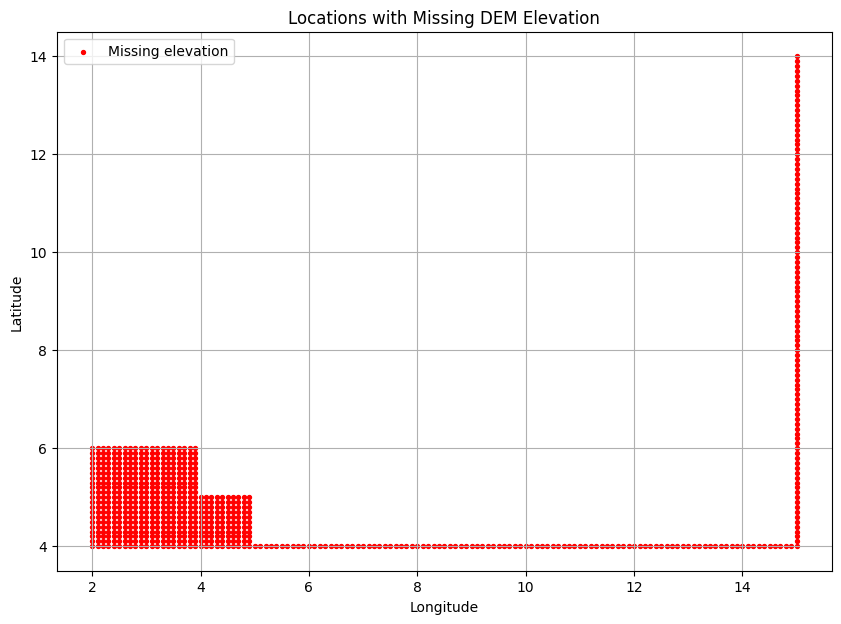

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    ds.longitude.values[np.where(missing)[1]],
    ds.latitude.values[np.where(missing)[0]],
    s=8,
    color="red",
    label="Missing elevation"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Locations with Missing DEM Elevation")
plt.legend()
plt.grid()

plt.show()

In [ ]:

import requests
import rasterio
from pathlib import Path

DEM_DIR = Path(
    "/content/drive/MyDrive/Nigeria_Temperature_Project/DEM/tiles"
)
DEM_DIR.mkdir(parents=True, exist_ok=True)

# The five missing 1-degree tiles
targets = [
    "N04_00_E002_00",
    "N04_00_E003_00",
    "N04_00_E004_00",
    "N05_00_E002_00",
    "N05_00_E003_00"
]

base_url = "https://copernicus-dem-30m.s3.amazonaws.com"

# Check which tiles are available
catalogue_url = f"{base_url}/tileList.txt"
response = requests.get(catalogue_url, timeout=60)
response.raise_for_status()

catalogue = response.text

for tile in targets:
    name = f"Copernicus_DSM_COG_10_{tile}_DEM"
    output = DEM_DIR / f"{name}.tif"

    if output.exists():
        print("Already exists:", name)
        continue

    if name not in catalogue:
        print("Not listed in catalogue:", name)
        continue

    url = f"{base_url}/{name}/{name}.tif"

    print("Downloading:", name)

    with requests.get(url, stream=True, timeout=180) as r:
        r.raise_for_status()

        with open(output, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    # Verify that the downloaded file opens correctly
    with rasterio.open(output) as src:
        print("Verified:", output.name, src.width, "x", src.height)


Not listed in catalogue: Copernicus_DSM_COG_10_N04_00_E002_00_DEM
Not listed in catalogue: Copernicus_DSM_COG_10_N04_00_E003_00_DEM
Not listed in catalogue: Copernicus_DSM_COG_10_N04_00_E004_00_DEM
Not listed in catalogue: Copernicus_DSM_COG_10_N05_00_E002_00_DEM
Not listed in catalogue: Copernicus_DSM_COG_10_N05_00_E003_00_DEM


In [ ]:
# Inspect the actual catalogue response

print("HTTP status:", response.status_code)
print("\nCatalogue preview:")
print(catalogue[:500])

print("\nSearch for our five tiles:")

for tile in targets:
    matches = [
        line for line in catalogue.splitlines()
        if tile in line
    ]
    print(tile, ":", matches[:2])

HTTP status: 200

Catalogue preview:
Copernicus_DSM_COG_10_N00_00_E006_00_DEM
Copernicus_DSM_COG_10_N00_00_E009_00_DEM
Copernicus_DSM_COG_10_N00_00_E010_00_DEM
Copernicus_DSM_COG_10_N00_00_E011_00_DEM
Copernicus_DSM_COG_10_N00_00_E012_00_DEM
Copernicus_DSM_COG_10_N00_00_E013_00_DEM
Copernicus_DSM_COG_10_N00_00_E014_00_DEM
Copernicus_DSM_COG_10_N00_00_E015_00_DEM
Copernicus_DSM_COG_10_N00_00_E016_00_DEM
Copernicus_DSM_COG_10_N00_00_E017_00_DEM
Copernicus_DSM_COG_10_N00_00_E018_00_DEM
Copernicus_DSM_COG_10_N00_00_E019_00_D

Search for our five tiles:
N04_00_E002_00 : []
N04_00_E003_00 : []
N04_00_E004_00 : []
N05_00_E002_00 : []
N05_00_E003_00 : []
